# Artificial project data
The [MT dataset](https://www.projectmanagement.ugent.be/research/project_scheduling/rcpsp) was initially created to test the algorithms presented in the book *Measuring Time* [1] and has since been used some studies [2]. In this work, we use a subset of 900 Activity-on-the-Node (AoN) networks, each containing 30 activities with randomly assigned durations and costs. The topological structure of these networks is determined by the SP-factor, which ranges from 0.1 to 0.9 in increments of 0.1 (100 networks generated for each SP value).

The SP-factor, proposed by Vanhoucke alongside other topological complexity indicators [3], is used to estimate the difficulty of a project scheduling problem. Since the original dataset does not include these indicators for all samples, we calculate them in this notebook.

> References:
> 1. Vanhoucke, M. (2009). Measuring time: Improving project performance using earned value management (Vol. 136). Springer Science & Business Media.
> 2. Wauters, M., & Vanhoucke, M. (2014). Support vector machine regression for project control forecasting. Automation in Construction, 47, 92-106.
> 3. Vanhoucke, M., Coelho, J., Debels, D., & Tavares, L. (2004). On the morphological structure of a network.

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import os

In [54]:
from network_tools import read_dag_file, compute_topological_indicators

In [55]:
sns.set_theme(palette='tab10')

## Topological complexity of the dataset

In [56]:
# Read the original dataset of networks and compute the topological indicators
root, _, files = next(os.walk('dataset\\Set 1 SP'))
networks = [(file.split('.')[0],os.path.join(root, file)) for file in files]

for project_name, project_path in networks:
    
    #print(f"Processing {project_name}")
    if not os.path.exists(os.path.join('./data/',project_name)):
        os.makedirs(os.path.join('./data/',project_name))
    G = read_dag_file(project_path)
    sp, ad, la, tf = compute_topological_indicators(G)

    # Save the topological indicators
    pd.DataFrame([[G.number_of_nodes(),G.number_of_edges(),nx.density(G),
                   np.mean(list(nx.get_node_attributes(G,'duration0').values())),
                   np.std(list(nx.get_node_attributes(G,'duration0').values())),
                   sp, ad, la, tf]],
                 columns=['Nodes','Edges','Density','MeanD','StdD','SP','AD','LA','TF']).to_csv(f"./data/{project_name}/{project_name}_topological_indicators.csv", index=False)

In [57]:
# Concatenate all the topological indicators
df_net=pd.concat([pd.read_csv(f"./data/{project_name}/{project_name}_topological_indicators.csv") for project_name, _ in networks])
df_net.reset_index(drop=True, inplace=True)

In [58]:
# SP distribution
df_net['SP'].value_counts()

SP
0.068966    100
0.172414    100
0.275862    100
0.379310    100
0.482759    100
0.586207    100
0.689655    100
0.793103    100
0.896552    100
Name: count, dtype: int64

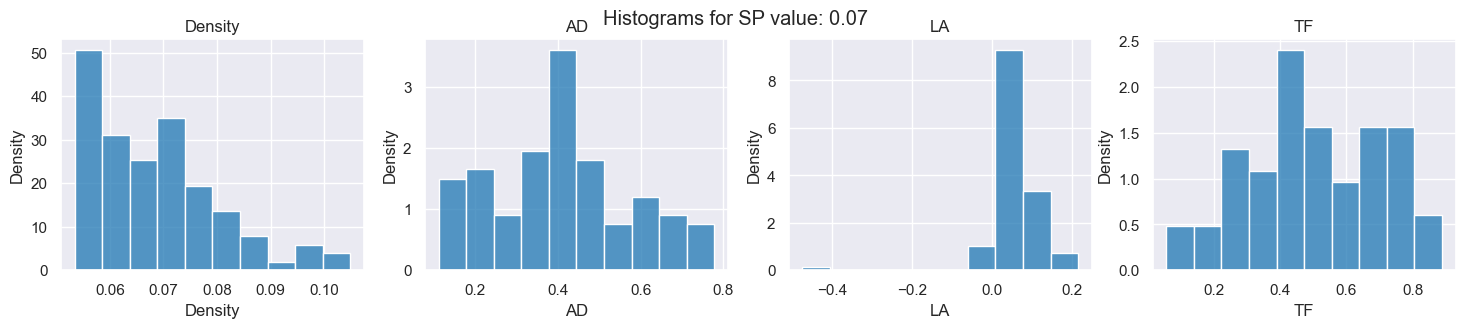

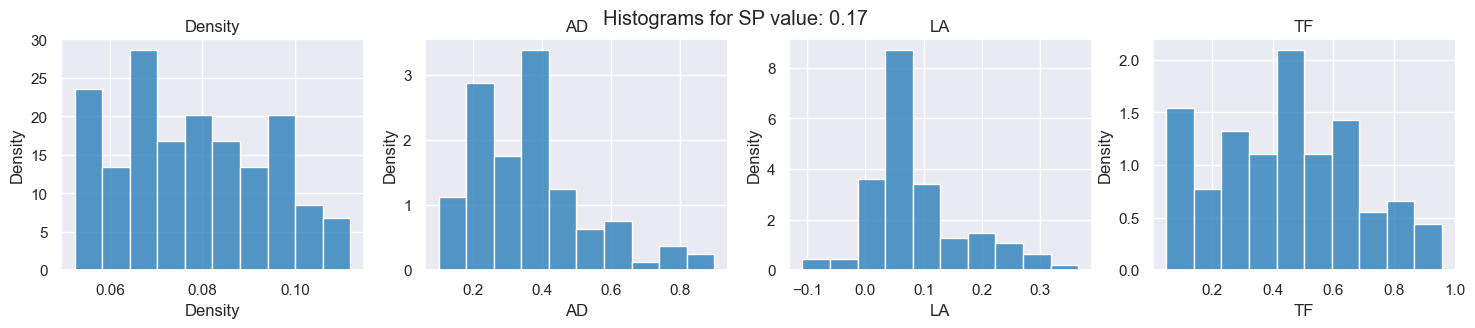

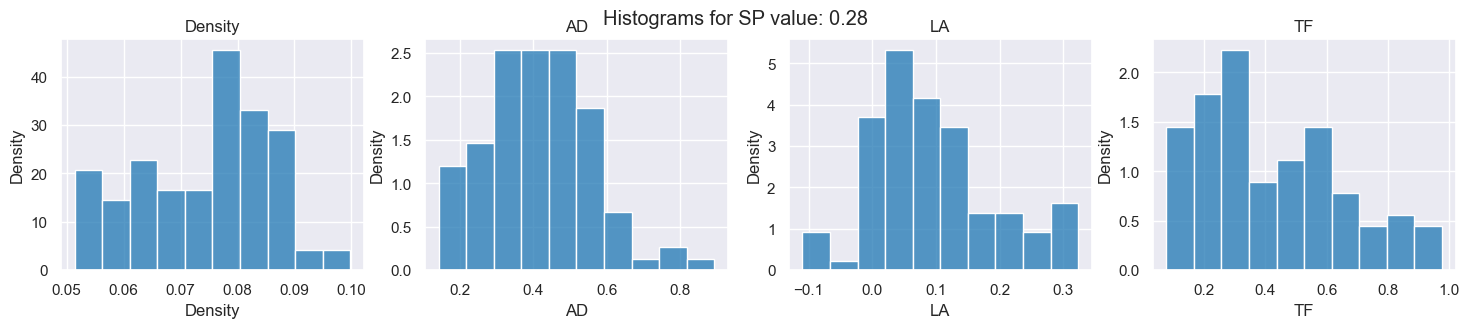

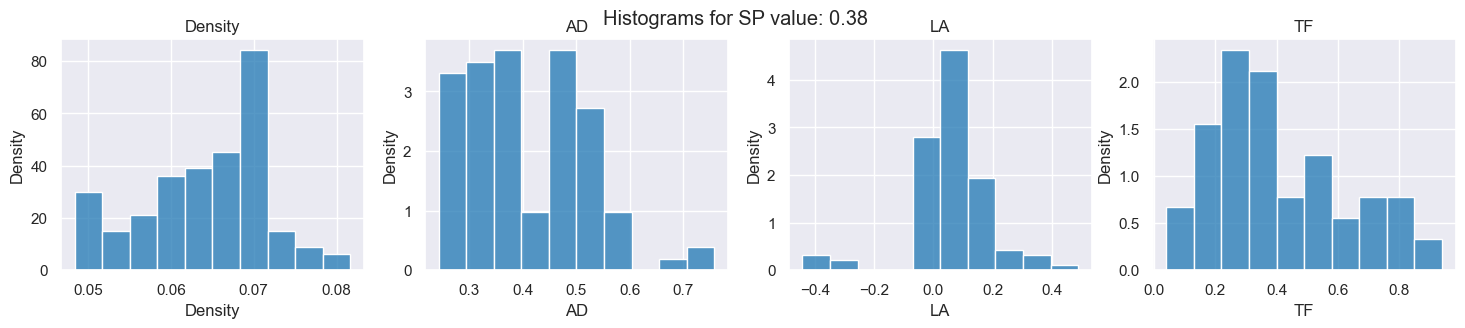

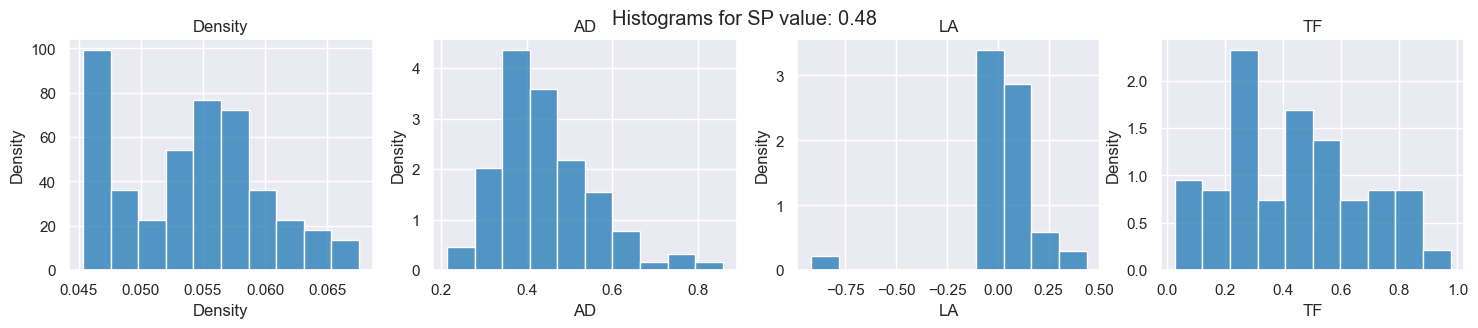

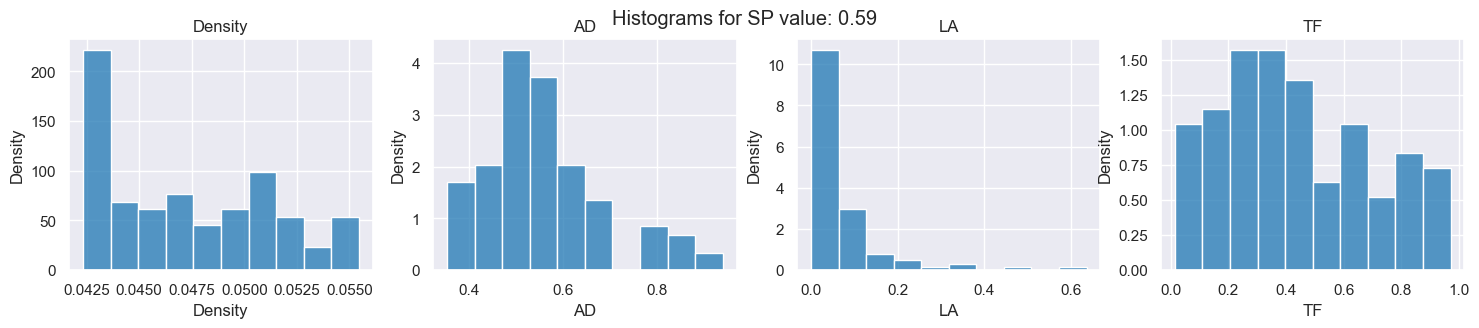

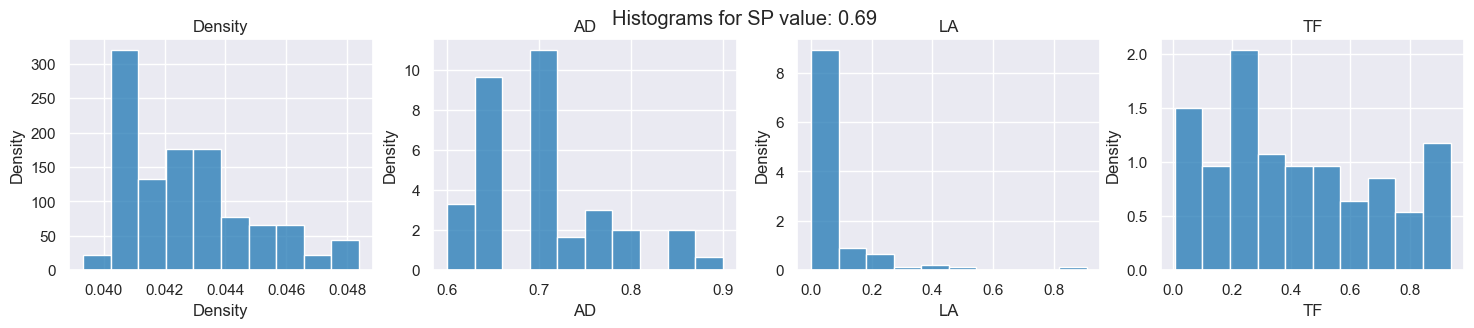

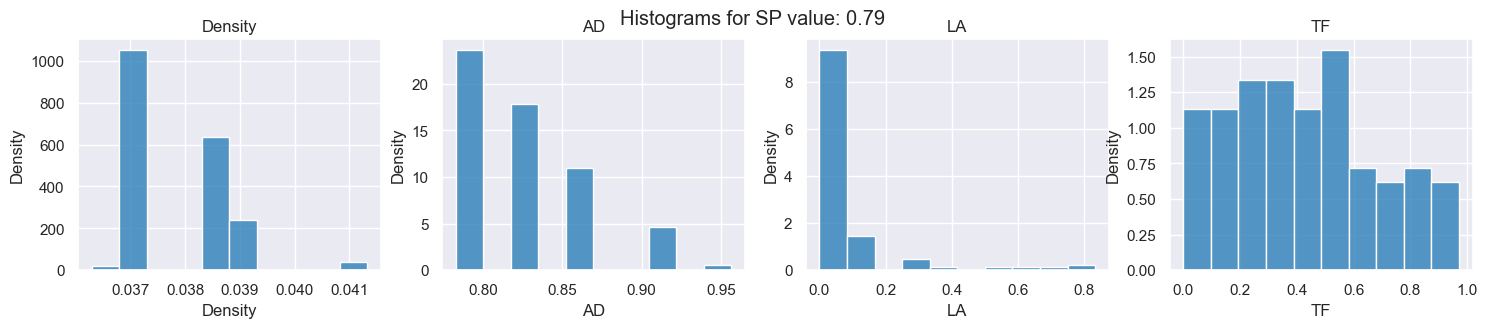

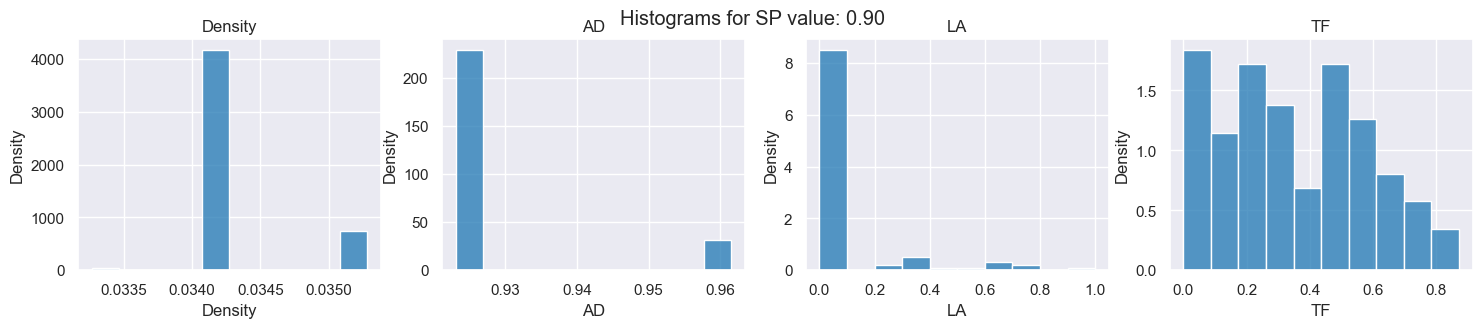

In [59]:
# Histograms of the topological indicators for each SP value
variables = ['Density', 'AD', 'LA', 'TF']
for sp in df_net['SP'].unique():
    subset = df_net[df_net['SP'] == sp]
    fig, axes = plt.subplots(1, len(variables), figsize=(18, 3))
    fig.suptitle(f'Histograms for SP value: {sp:.2f}')
    for i, var in enumerate(variables):
        sns.histplot(subset[var], bins=10, ax=axes[i],stat='density')
        axes[i].set_title(var)
    plt.show()

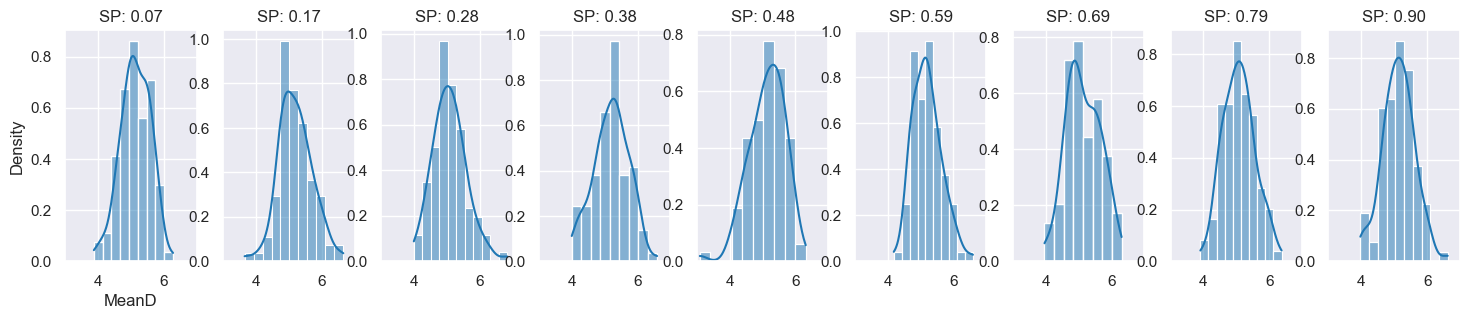

In [60]:
# Histogram of the the mean durations for each SP value
plt.figure(figsize=(18, 3))
for i,sp in enumerate(df_net['SP'].unique()):
    subset = df_net[df_net['SP'] == sp]
    plt.subplot(1,9,i+1)
    sns.histplot(subset['MeanD'], stat='density',kde=True)
    if i==0:
        plt.ylabel('Density')
        plt.xlabel('MeanD')
    else:
        plt.ylabel('')
        plt.xlabel('')
    plt.xlim(3,7)
    plt.title(f'SP: {sp:.2f}')
plt.show()